<a href="https://colab.research.google.com/github/adalves-ufabc/2026.Q3-PLN/blob/main/2026_Q3_PLN_AULA_16_Notebook_34.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Processamento de Linguagem Natural [2026-Q3]**
Prof. Alexandre Donizeti Alves

## **Agentes [LangChain]**
---



**Agentes** são componentes que usam cadeias (*chains*) para interagir com o ambiente, tomar decisões e realizar ações com base em entradas dinâmicas. Eles funcionam como controladores que orquestram o comportamento de diferentes partes do sistema, utilizando modelos de linguagem, ferramentas (*tools*) externas e cadeias personalizadas para cumprir uma tarefa específica.

**Principais Características dos Agentes no LangChain:**

* **Tomada de Decisões Dinâmica**: ao contrário de uma cadeia estática, que segue um fluxo pré-definido, **agentes** podem tomar decisões sobre quais ações realizar ou quais ferramentas utilizar, dependendo das entradas que recebem e dos resultados intermediários.

* **Integração com Ferramentas**: agentes podem ser configurados para interagir com ferramentas externas, como APIs, bancos de dados, navegadores web, entre outros. Isso permite que o agente realize tarefas complexas que exigem interação com sistemas externos.

Os **agentes** permitem que o modelo use as ferramentas de forma iterativa, decidindo quantas vezes e em que ordem usá-las durante o processo.

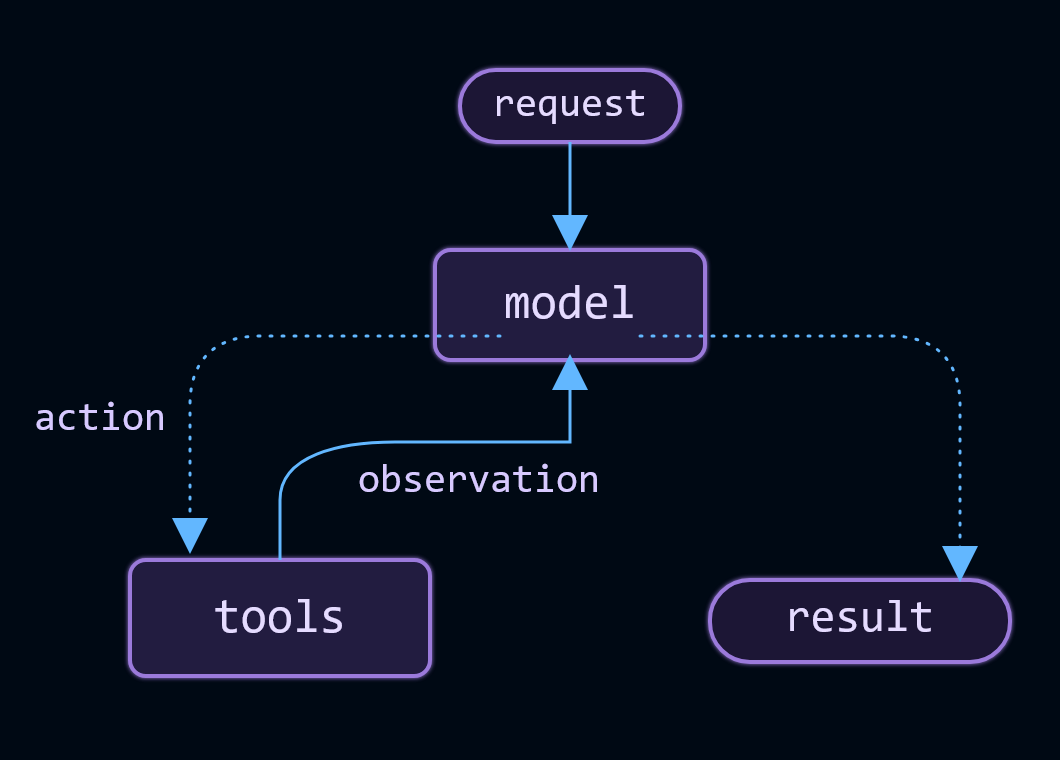

**IMPORTANTE:**

Por si só, modelos de linguagem não podem realizar ações - eles apenas geram texto.
>
Um grande caso de uso do **LangChain** é a criação de agentes. **Agentes** são sistemas que usam um LLM como motor de raciocínio para determinar quais ações tomar e quais devem ser as entradas para essas ações. Os resultados dessas ações podem então ser reinseridos no agente, que decide se mais ações são necessárias ou se pode finalizar.

#### **LangChain**

In [ ]:
#@title Instalando o pacote LangChain

!pip install langchain

In [ ]:
#@title Versão do LangChain

import langchain

print(langchain.__version__)

1.4.8


In [ ]:
#@title Integração com o pacote da OpenAI

!pip install langchain-openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.1/588.1 kB 11.7 MB/s  0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langchain-openai]


In [ ]:
#@title Definindo a chave da API da OpenAI
from getpass import getpass

OPENAI_API_KEY = getpass()

··········


#### **Exemplos**

Primeiro, definiremos um modelo e uma ferramenta, e então usaremos esses para criar um agente.

In [ ]:
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI(model="gpt-6-luna", api_key=OPENAI_API_KEY)

In [ ]:
from langchain.tools import tool

@tool
def funcao_magica(entrada: int) -> int:
    """Aplica uma função mágica a uma entrada."""
    return entrada + 2

# lista de ferramentas
ferramentas = [funcao_magica]

consulta = "qual é o valor de funcao_magica(3)?"

O agente pode ser invocado da seguinte forma:

In [ ]:
from langchain.agents import create_agent

agente = create_agent(modelo, tools=ferramentas)

resposta = agente.invoke({
    "messages": [
        {"role": "system", "content": "Você é um assistente útil."},
        {"role": "human", "content": consulta}
    ]
})

In [ ]:
resposta

{'messages': [SystemMessage(content='Você é um assistente útil.', additional_kwargs={}, response_metadata={}, id='0e575abc-c5d5-4313-a1ef-d57d81770643'),
  HumanMessage(content='qual é o valor de funcao_magica(3)?', additional_kwargs={}, response_metadata={}, id='440c5d70-0a9d-4732-a8ce-ee596a793097'),
  AIMessage(content=[{'arguments': '{"entrada":3}', 'call_id': 'call_ip5NdEKVWDJlSM4MkLjyduSa', 'name': 'funcao_magica', 'type': 'function_call', 'id': 'fc_0eb7793d7f216c7e006afb0523217487d2afc24a71d6f0129e', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_0eb7793d7f216c7e006afb0522001c87d2aaaa3a88bc23da09', 'created_at': 1794835746.0, 'metadata': {}, 'model': 'gpt-6-luna', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-6-luna'}, id='resp_0eb7793d7f216c7e006afb0522001c87d2aaaa3a88bc23da09', tool_calls=[{'name': 'funcao_magica', 'args': {'entrada': 3}, 'id': 'call_ip5NdEKVWDJlSM4MkLjyduSa

In [ ]:
resposta["messages"][-1].content

[{'type': 'text',
  'text': 'O valor de `funcao_magica(3)` é **5**.',
  'annotations': [],
  'id': 'msg_0eb7793d7f216c7e006afb0524809887d28fe48760b7b65713',
  'phase': 'final_answer'}]

In [ ]:
# Histórico da primeira resposta
mensagens_historico = resposta["messages"]

# Nova pergunta do usuário
nova_consulta = "Não entendi!"

# Invocando o agente novamente com o histórico + nova mensagem
nova_resposta = agente.invoke({
    "messages": mensagens_historico + [
        {"role": "human", "content": nova_consulta}
    ]
})

In [ ]:
resultado = {
    "input": nova_consulta,
    "output": nova_resposta["messages"][-1].content
}

print(resultado)

{'input': 'Não entendi!', 'output': [{'id': 'rs_0eb7793d7f216c7e006afb0539b06887d2a0da3fcc294b68f1', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq-wU6EHlE-VdOSY1-EOWr2W8q6OwqZJgxlbySbV4l8QDilNednzm2lwzfuCZfeRF0EHdWGcGF7kAb0L9Fg2uyUwrG9nfcOmYF3LST3Rgbf8kbXF6q7mv411zzL4ea9GFeskpK0uG_PtUGitbOC6fCMYejfo1X69sYZPcf6fBJN9YvnbG0oBI_Gi63SXPbQppcfZHcz4s6cwppjGapViUw9poWsBhJiGWtoRHyxRBmQOj5YvqEHqyXB4-QZJ_u2z2YllYAizNO1n_jqDa2BlQC3XIMUcrHkh9wgm5bkqaB9lE3HGIAdUj8wcUqCcoBphb6z79revaPpGywyrdtxRNsP3UoYO1AVCxnXHbMuvu_rPSuXOoSAacmpdmOC6Q3j0hKNG790fUOYk7TbjOsl80sHJNPyLOGz6aa6FO-zebKBPx9VYbiQheznThYXI7tlMdvlQPyeSzrlAwYlLVinXh877IaNoOgrIVw9yAvA3ShR0jv30y21jZmK17JqW76CMVLvIXQk8rIwVGjrZXuhzlA65ojccgB-MSI3ubJk5nnpM_CZMvPPecEuClh_i-ZnevLISJ3zkek83f4_3_WTTpEj0xRcIYygBrDDOobqYpvl-R9yZNduYv1CAp5hhbRwFMRaW6BViAVVg5jRYm7YhtsdPrPiBAtEv7QvU_9jPHAFE1jheCEqHDxD8e_pkN4Z7YYqQqrPe0DrKVTIo9ELNCJLc8Z-5C_wRqHxlhovXrt56L_V1gL_Q1t4g906zvikk62nxNhtkGM0nGQW4vQ99jBOEI5KbavBufwzRIq6VeUqk1F4Bh4Se

In [ ]:
resultado["output"]

[{'id': 'rs_0eb7793d7f216c7e006afb0539b06887d2a0da3fcc294b68f1',
  'summary': [],
  'type': 'reasoning',
  'content': [],
  'encrypted_content': 'gAAAAABq-wU6EHlE-VdOSY1-EOWr2W8q6OwqZJgxlbySbV4l8QDilNednzm2lwzfuCZfeRF0EHdWGcGF7kAb0L9Fg2uyUwrG9nfcOmYF3LST3Rgbf8kbXF6q7mv411zzL4ea9GFeskpK0uG_PtUGitbOC6fCMYejfo1X69sYZPcf6fBJN9YvnbG0oBI_Gi63SXPbQppcfZHcz4s6cwppjGapViUw9poWsBhJiGWtoRHyxRBmQOj5YvqEHqyXB4-QZJ_u2z2YllYAizNO1n_jqDa2BlQC3XIMUcrHkh9wgm5bkqaB9lE3HGIAdUj8wcUqCcoBphb6z79revaPpGywyrdtxRNsP3UoYO1AVCxnXHbMuvu_rPSuXOoSAacmpdmOC6Q3j0hKNG790fUOYk7TbjOsl80sHJNPyLOGz6aa6FO-zebKBPx9VYbiQheznThYXI7tlMdvlQPyeSzrlAwYlLVinXh877IaNoOgrIVw9yAvA3ShR0jv30y21jZmK17JqW76CMVLvIXQk8rIwVGjrZXuhzlA65ojccgB-MSI3ubJk5nnpM_CZMvPPecEuClh_i-ZnevLISJ3zkek83f4_3_WTTpEj0xRcIYygBrDDOobqYpvl-R9yZNduYv1CAp5hhbRwFMRaW6BViAVVg5jRYm7YhtsdPrPiBAtEv7QvU_9jPHAFE1jheCEqHDxD8e_pkN4Z7YYqQqrPe0DrKVTIo9ELNCJLc8Z-5C_wRqHxlhovXrt56L_V1gL_Q1t4g906zvikk62nxNhtkGM0nGQW4vQ99jBOEI5KbavBufwzRIq6VeUqk1F4Bh4SecZXzbNGCxTkYY9rpN4XJRjXNDn6k

Vamos ver outro exemplo:

In [ ]:
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI(model="gpt-6-luna", api_key=OPENAI_API_KEY)

In [ ]:
from langchain.tools import tool

@tool
def multiplicar(primeiro_int: int, segundo_int: int) -> int:
    """Multiplica dois números inteiros."""
    return primeiro_int * segundo_int

@tool
def adicionar(primeiro_int: int, segundo_int: int) -> int:
    """Soma dois números inteiros."""
    return primeiro_int + segundo_int

@tool
def exponenciar(base: int, expoente: int) -> int:
    """Exponencia a base elevada ao expoente."""
    return base ** expoente

ferramentas = [multiplicar, adicionar, exponenciar]

In [ ]:
consulta = "Faça 3 elevado à quarta potência e multiplique pela soma de sete e três e, em seguida, eleve ao quadrado o resultado total"

agente = create_agent(modelo, tools=ferramentas)

In [ ]:
resposta = agente.invoke({
    "messages": [
        {"role": "human", "content": consulta}
    ]
})

In [ ]:
resposta["messages"][-1].content

[{'type': 'text',
  'text': '\\(3^4 = 81\\) e \\(7+3=10\\). Multiplicando: \\(81\\times10=810\\). Elevando o resultado ao quadrado: \\(810^2=\\boxed{656\\,100}\\).',
  'annotations': [],
  'id': 'msg_0d8d961e4fabd795006afb05890d0c87d291efe9bd64853850',
  'phase': 'final_answer'}]

In [ ]:
from IPython.core.display import Markdown

display(Markdown(resposta["messages"][-1].text))

\(3^4 = 81\) e \(7+3=10\). Multiplicando: \(81\times10=810\). Elevando o resultado ao quadrado: \(810^2=\boxed{656\,100}\).

In [ ]:
len(resposta["messages"])

9

In [ ]:
resposta["messages"][0].content

'Faça 3 elevado à quarta potência e multiplique pela soma de sete e três e, em seguida, eleve ao quadrado o resultado total'

In [ ]:
resposta["messages"][0].type

'human'

In [ ]:
for msg in resposta["messages"]:
    print(msg)

content='Faça 3 elevado à quarta potência e multiplique pela soma de sete e três e, em seguida, eleve ao quadrado o resultado total' additional_kwargs={} response_metadata={} id='13bcee3f-7ea5-4ef2-a57e-f2de03b9b108'
content=[{'id': 'rs_0d8d961e4fabd795006afb0583992087d2a2e6fe46726c003d', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq-wWF9BaSOGHNY5GdWJTh2oJPXmhb68lKqU9zWLiT7FFQGWcOmXs3D-iQX7f_2ssae76KXzLqAMDokeiEXqptoyETuCxdxKbW4Xh5bQ8fD-SV-2ysW4SDe2j7hvGnKIRtTCH6BvGNAxUoyc1jObptbyiRZAxdYVMoxjEGDC8xjpOndkARKcn4D5Fysv19_IdKK9JAABFjLpGhsOqDX4d9_mz5FeZjiKP8lOwyHl-AK306aSqbz-pOah1BlttmimBoOGLWX06kObwNzrhGXpKiAdNmd796ujL6ftPEarrvg9QIs5XldghNGXYgjR0bVc-NIhBe-X2fCcjc9Adl74oZW5nbSK7Jbl2EarURijH4vjnvx-OUwoLj5bCExd3-Kp4m5GDLwNYS6S3h9hwdsJa-9zdGwUZDz0eQljpNXkosl16gceiYDCSOmdGG13O80cTHDzR8V9In9jwSxXwuU9Ea221gLYAsseIPbzjXKjsXTXHL-4Pss_69jKZgEMCKYZpGpBVOQHNvWNk5LEsbiYoB6QGfkrfyih8tN6iu9QeA8_K1zzrzzChB4BMMDLyz-oauqUp-Wq5Aq4CtYfTQV8mgSS2E1YykJYBTKGQCZyQiQ-tUYvEbosppv

In [ ]:
for msg in resposta["messages"]:
    print(msg.type)

human
ai
tool
tool
ai
tool
ai
tool
ai


Mais um exemplo:

In [ ]:
from langchain.tools import tool
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI( model = "gpt-6-luna", max_tokens = 1000, api_key = OPENAI_API_KEY )

@tool
def pesquisar(pais: str) -> str:
    """Pesquisar informações sobre um país."""
    return f"Resultados para: {pais}"

@tool
def obter_clima(localizacao: str) -> str:
    """Obter informações meteorológicas de uma localização."""
    return f"Clima em {localizacao}: Frio, 12°C"

agente = create_agent(modelo, tools=[pesquisar, obter_clima])

In [ ]:
resposta = agente.invoke(
    {"messages": [{"role": "human", "content": "Como está o clima em Santo André?"}]}
)

In [ ]:
resposta

{'messages': [HumanMessage(content='Como está o clima em Santo André?', additional_kwargs={}, response_metadata={}, id='da8bf2a8-5f48-4641-81d8-1cf96c75e1a8'),
  AIMessage(content=[{'arguments': '{"localizacao":"Santo André"}', 'call_id': 'call_LvPVivXLiqHtSCzloum3kejH', 'name': 'obter_clima', 'type': 'function_call', 'id': 'fc_0258d8b73ac7b9f5006afb063f6bbc87d2b0fb5d6e4c6e2c15', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_0258d8b73ac7b9f5006afb063e4a9087d2b86741318e885ed4', 'created_at': 1794836030.0, 'metadata': {}, 'model': 'gpt-6-luna', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-6-luna'}, id='resp_0258d8b73ac7b9f5006afb063e4a9087d2b86741318e885ed4', tool_calls=[{'name': 'obter_clima', 'args': {'localizacao': 'Santo André'}, 'id': 'call_LvPVivXLiqHtSCzloum3kejH', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 75, 'output_tokens': 23, 'total_tok

In [ ]:
for msg in resposta["messages"]:
    print(msg.type)

human
ai
tool
ai


In [ ]:
print(resposta["messages"][-1].content)

[{'type': 'text', 'text': 'Em Santo André, está frio: 12 °C.', 'annotations': [], 'id': 'msg_0258d8b73ac7b9f5006afb06407b6487d2aad90754b6cd3221', 'phase': 'final_answer'}]


In [ ]:
print(resposta["messages"][0].content)

Como está o clima em Santo André?


In [ ]:
resposta = agente.invoke(
    {"messages": [{"role": "human", "content": "Pesquisar informações do país Egito"}]}
)

In [ ]:
print(resposta["messages"][-1].content)

[{'id': 'rs_04de6566e46e408c006afb065555c487d290e4ccba4cacc80e', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq-wZZyvhMQeywz9zVUoAb8ll6sXcWCmfF0vKY0hxctnTi6lDLxZA14xpuz1YPBVtPVB3Cwzzovib1eFSuKoMLJnVBkQVFSV9GQSxGg5nBxatsk4MV73cg6Pv4QNiSIwdHqYYjieJebvYVqo_JnVg7XVgBbDV66rPCzyI62uBcuPRRbXQ4bQDlWACPgRzLMWInTeW1tuVJeM3yxTHPQvZ6rZuQXWcHmg2-BaJAcLJK3JH2E8f_0lrwBu8RvE3p8N2jffssvxdpxEAU3351uHzMvTlSnLFX37_OKtflrwLCEJWBnifttnAXj0ikxF4njOtuggCgCkQtK1wHI7Hih-WDF0n_CkaOy93gZAQf_461TjJ_aq54qBdbbk3lFUwqNV-y-2zwE7ueUd0vqwUkRNBTnqbiWaCXoXNl3ctrQJOiBLMBCdHrd7pfvMhGJEZ18IoJ3XMKfzTe5zpzn9HVNkQmYeO58DB6_VXAKj8RGEmjWzgSqvf0TMYenTZS7o4ncTQjGXJpycEsOiEZbjhyoA8nEdi4ZFlUotl3Ia3as_I3rZ1Iwjdgt40ogZu2d29euZaDSsgep-qyPwbhpRN_80yRmUwAkxT1k7G_4AAkoEV72WuxUoIVtk_nXiEfC_9WLv4IJ6gowGI6Gs2W2RALrasheFS4GnTaJv9wzoi5CmtGVLBbCIE4-bN6lzTN3ZGTyK8lJNAJKOmZZe5YB77mCdlIYY_4Gdu6vAcXenGkb9kS1vqJ2qbhPdMM25isrcJhidjQebaoBXZrA-3r7J2sZ_GOD6ywXu49Te5pzOkf5-lyod5bc5cb7xJUIW7Uf3gaVnlDFhrSvnOnnfbl007EUabXt6

In [ ]:
for msg in resposta["messages"]:
    print(msg.type)

human
ai
tool
ai


**Saída Estruturada**

Em algumas situações, você pode querer que o agente retorne uma saída em um formato específico. O **LangChain** fornece estratégias para saída estruturada por meio do parâmetro `response_format`.

*`ToolStrategy`*


*`ToolStrategy`* utiliza chamadas de ferramenta artificiais para gerar saída estruturada. Isso funciona com qualquer modelo que suporte chamadas de ferramenta:

*`ProviderStrategy`*

*`ProviderStrategy`* utiliza a geração de saída estruturada nativa do provedor do modelo. Isso é mais confiável, mas funciona apenas com provedores que oferecem suporte à saída estruturada nativa (por exemplo, OpenAI):

In [ ]:
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI(model="gpt-6-luna", api_key=OPENAI_API_KEY)

In [ ]:
from langchain.tools import tool
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy

@tool
def pesquisar(consulta: str) -> str:
    """Pesquisar informações."""
    return f"Resultados para: {consulta}"

class InfoContato(BaseModel):
    """Informações de contato de uma pessoa."""
    nome: str = Field(description="O nome da pessoa")
    email: str = Field(description="O endereço de e-mail da pessoa")
    telefone: str = Field(description="O número de telefone da pessoa")

agente = create_agent(
    model = modelo,
    tools = [pesquisar],
    response_format = ToolStrategy(InfoContato)
)

resultado = agente.invoke({
    "messages": [
        {"role": "human", "content": "Extraia as informações de contato de: John Doe, john@example.com, (555) 123-4567"}
    ]
})

In [ ]:
resultado["structured_response"]

InfoContato(nome='John Doe', email='john@example.com', telefone='(555) 123-4567')

In [ ]:
for msg in resultado["messages"]:
    print(msg.type)

human
ai
tool


Outro exemplo:

In [ ]:
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI(model="gpt-6-luna", api_key=OPENAI_API_KEY)

In [ ]:
from pydantic import BaseModel, Field
from typing import Literal
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from langchain.tools import tool

@tool
def pesquisar(consulta: str) -> str:
    """Pesquisar informações."""
    return f"Resultados para: {consulta}"

class AnaliseProduto(BaseModel):
    """Análise de uma avaliação de produto."""
    avaliacao: int | None = Field(
        description="A nota do produto", ge=1, le=5
    )
    sentimento: Literal["positivo", "negativo"] = Field(
        description="O sentimento da avaliação"
    )
    pontos_chave: list[str] = Field(
        description="Os pontos principais da avaliação. Minúsculas, 1-3 palavras cada."
    )

agente = create_agent(
    model = modelo,
    tools = [pesquisar],
    response_format = ToolStrategy(AnaliseProduto)
)

resultado = agente.invoke({
    "messages": [
        {"role": "user", "content": "Analise esta avaliação: 'Ótimo produto: 5 de 5 estrelas. Entrega rápida, mas caro'"}
    ]
})

In [ ]:
resultado["structured_response"]

AnaliseProduto(avaliacao=5, sentimento='positivo', pontos_chave=['produto ótimo', 'entrega rápida', 'preço alto'])